In [37]:
import numpy as np
import pandas as pd
import math
from uncertainties import unumpy as unp
from uncertainties import ufloat as uf
import numpy as np
import uncertainties.umath as umath
import matplotlib.pyplot as plt
from scipy import stats




def plot_linear_fit(x, y, xlabel=None, ylabel=None, title=None):
    """Scatter plot of x vs y with a linear regression line.

    x, y : pandas Series (or single-column DataFrames)

    Returns
    -------
    slope, intercept : uncertainties.ufloat
    """
    x = np.asarray(x, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    res = stats.linregress(x, y)
    slope = uf(res.slope, res.stderr)
    intercept = uf(res.intercept, res.intercept_stderr)

    x_fit = np.linspace(0.9 * x.min(), 1.1 * x.max(), 200)
    y_fit = res.slope * x_fit + res.intercept

    fig, ax = plt.subplots()
    ax.scatter(x, y, label="Data")
    ax.plot(
        x_fit, y_fit, color="red",
        label=f"Fit: y = ({slope:.2uP})x + ({intercept:.2uP})\n"
              f"$R^2$ = {res.rvalue**2:.4f}",
    )

    ax.set_xlim(0.9 * x.min(), 1.1 * x.max())
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if title:  ax.set_title(title)
    ax.legend()
    plt.show()

    return slope, intercept

In [31]:
import numpy as np
import pandas as pd

data = {
    "Room":     {"Resistance": 105.5, "Pressure": 302, "Temperature": 293},
    "Dry_Ice":  {"Resistance": 69.1, "Pressure": 200.08, "Temperature": 195},
    "LiquidN2": {"Resistance": 20.1, "Pressure": 17, "Temperature": 77},
    "Ice":      {"Resistance": 101.5 , "Pressure": 270, "Temperature": 273},
    "Boil":     {"Resistance": 136.1, "Pressure": 398, "Temperature": 373},
}

# orient="index" makes the outer keys the rows and the inner keys the columns
df = pd.DataFrame.from_dict(data, orient="index")
T_tp = 276
exp_coeff = 5.7e-5
df["Pressure"] =  (df["Pressure"] +101)*(1+(df["Temperature"]-276)*exp_coeff)
df["Temp_C"] = df["Temperature"]-276
print(df)



          Resistance    Pressure  Temperature  Temp_C
Room           105.5  403.390507          293      17
Dry_Ice         69.1  299.689914          195     -81
LiquidN2        20.1  116.661526           77    -199
Ice            101.5  370.936559          273      -3
Boil           136.1  501.758971          373      97


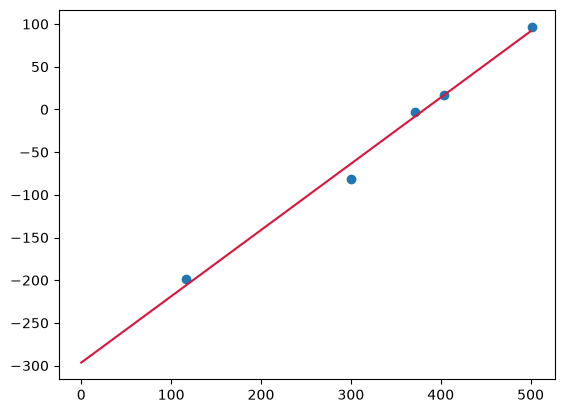

-296+/-14


In [27]:
reg = stats.linregress(df["Pressure"], df["Temp_C"])

T_zero = uf(reg.intercept, reg.intercept_stderr)

plt.scatter(df["Pressure"], df["Temp_C"])

x_line = np.linspace(0, 500)
y_line = x_line*reg.slope + reg.intercept

plt.plot(x_line, y_line, color="crimson")

plt.show()

print(T_zero)

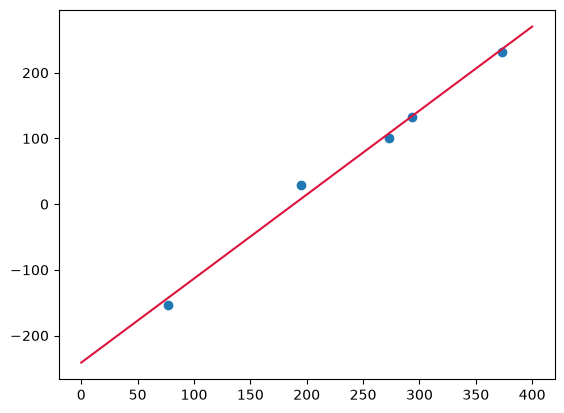

1.28+/-0.07


In [25]:
df["Delta_P"] = df["Pressure"] - 270

reg = stats.linregress(df["Temperature"], df["Delta_P"])

alpha_v = uf(reg.slope, reg.stderr)

plt.scatter(df["Temperature"], df["Delta_P"])

x_line = np.linspace(0, 400)
y_line = x_line*reg.slope + reg.intercept

plt.plot(x_line, y_line, color="crimson")

plt.show()
print(alpha_p)

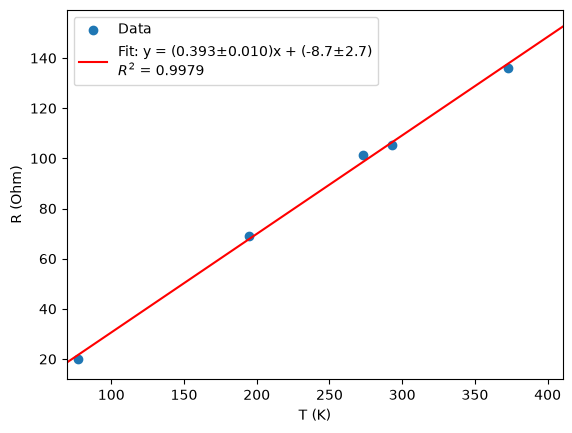

0.393+/-0.010


In [40]:
beta, intercept = plot_linear_fit(df["Temperature"], df["Resistance"], "T (K)", "R (Ohm)")

print(beta)